<a href="https://colab.research.google.com/github/enslern/The-AI-engineer-course-2026-Complete-AI-bootcamp/blob/main/langgraph_graph_components_and_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Installing the dependencies and loading the api key**

In [ ]:
!pip install langchain==0.3.25
!pip install langgraph==0.4.8
!pip install langchain-groq
!pip install langgraph-checkpoint-sqlite==0.3.17
!pip install grandalf==0.8

In [69]:
import os
import sys

In [70]:
sys.path.append(os.path.abspath("/content/drive/MyDrive/Colab Notebooks/resources"))

In [71]:
import config

In [72]:
os.environ["GROQ_API_KEY"]=config.GROQ_API_KEY

# **Importing the relevant classes**

In [73]:
from langgraph.graph import START,END,StateGraph
from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage,BaseMessage
from langchain_core.runnables import Runnable
from collections.abc import Sequence

# **Define the state of the graph**

In [74]:
class State(TypedDict):
  messages:Sequence[BaseMessage]

In [75]:
state=State(messages=[HumanMessage(content="Who is Isaac Newton?")])

In [76]:
state["messages"][0].pretty_print()

================================ Human Message =================================

Who is Isaac Newton?


# **Define the node**

In [77]:
chat=ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    seed=365,
    max_tokens=100,
    reasoning_format="hidden",

)

/usr/local/lib/python3.13/dist-packages/pydantic/main.py:263: UserWarning: WARNING! seed is not default parameter.
                    seed was transferred to model_kwargs.
                    Please confirm that seed is what you intended.
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


In [78]:
response=chat.invoke(state["messages"])

In [79]:
response.pretty_print()

================================== Ai Message ==================================

Sir Isaac Newton (1642 – 1727) was an English mathematician, physicist, astronomer, alchemist, and theologian who is widely regarded as one of the most influential scientists in history. His major contributions include:

| Field | Key Contributions |
|-------|-------------------|
| **Mathemat


In [80]:
def chatbot(state:State)->State:
    print(f"\n----------Entering chatbot")
    response=chat.invoke(state["messages"])
    response.pretty_print()
    return State(messages=[response])

In [81]:
chatbot(state)


----------Entering chatbot
================================== Ai Message ==================================

Sir Isaac Newton (1642 – 1727) was an English mathematician, physicist, astronomer, alchemist, and theologian who is widely regarded as one of the most influential scientists in history. His major contributions include:

| Field | Key Contributions |
|-------|-------------------|
| **Mathemat


{'messages': [AIMessage(content='Sir Isaac Newton (1642\u202f–\u202f1727) was an English mathematician, physicist, astronomer, alchemist, and theologian who is widely regarded as one of the most influential scientists in history. His major contributions include:\n\n| Field | Key Contributions |\n|-------|-------------------|\n| **Mathemat', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 76, 'total_tokens': 176, 'completion_time': 0.208736135, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.004126474, 'prompt_tokens_details': None, 'queue_time': 0.141732686, 'total_time': 0.212862609}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_fe269835c7', 'service_tier': 'on_demand', 'finish_reason': 'length', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0a602-024c-7782-928e-257986b8d3bd-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens': 100, 'tota

# **Define the Graph**

In [82]:
graph=StateGraph(State)

In [83]:
graph.add_node("chatbot",chatbot)

In [84]:
graph.add_edge(START,"chatbot")
graph.add_edge("chatbot",END)

In [85]:
graph_compiled=graph.compile()

In [86]:
isinstance(graph_compiled,Runnable)

True

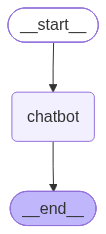

In [87]:
graph_compiled

###**Test graph**

In [88]:
graph_compiled.invoke(state)


----------Entering chatbot
================================== Ai Message ==================================

Sir Isaac Newton (1642 – 1727) was an English mathematician, physicist, astronomer, alchemist, and theologian who is widely regarded as one of the most influential scientists in history. His major contributions include:

| Field | Key Contributions |
|-------|-------------------|
| **Mathemat


{'messages': [AIMessage(content='Sir Isaac Newton (1642\u202f–\u202f1727) was an English mathematician, physicist, astronomer, alchemist, and theologian who is widely regarded as one of the most influential scientists in history. His major contributions include:\n\n| Field | Key Contributions |\n|-------|-------------------|\n| **Mathemat', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 76, 'total_tokens': 176, 'completion_time': 0.211259804, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.003193965, 'prompt_tokens_details': None, 'queue_time': 0.175143183, 'total_time': 0.214453769}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_49bfac06f1', 'service_tier': 'on_demand', 'finish_reason': 'length', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0a602-04a7-7080-97ba-59cbfe99720a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens': 100, 'tota

#**Conditional edges:Defining nodes and a routing function**

In [89]:
from typing import Literal

In [90]:
def ask_question(state:State)->State:
  print(f"\n--------- Entering ask_question:")
  print("wht is ur quesetion?")

  return State(messages=[HumanMessage(input())])

In [92]:
ask_question(State(messages=[]))


--------- Entering ask_question:
wht is ur quesetion?
hello


{'messages': [HumanMessage(content='hello', additional_kwargs={}, response_metadata={})]}

In [93]:
def ask_another_question(state:State)->State:
  print(f"\n--------- Entering ask_another_question:")
  print("would you like to ask another question (yes/no)?")

  return State(messages=[HumanMessage(input())])

In [94]:
ask_another_question(State(messages=[]))


--------- Entering ask_another_question:
would you like to ask another question (yes/no)?
yes


{'messages': [HumanMessage(content='yes', additional_kwargs={}, response_metadata={})]}

###**Define the routing function**

In [95]:
def routing_function(state:State)->str:
  if state["messages"][0].content=="yes":
    return "ask_question"
  else:
    return "__end__"

###**Define the graph**

In [105]:
graph = StateGraph(State)

graph.add_node("ask_question", ask_question)
graph.add_node("chatbot", chatbot)
graph.add_node("ask_another_question", ask_another_question)

graph.add_edge(START, "ask_question")
graph.add_edge("ask_question", "chatbot")
graph.add_edge("chatbot", "ask_another_question")
graph.add_conditional_edges(
    source="ask_another_question",
    path=routing_function,
    path_map={"ask_question": "ask_question", "__end__": "__end__"}
)

graph_compiled = graph.compile()

In [106]:
graph_compiled=graph.compile()

In [107]:
print(graph_compiled.get_graph().draw_ascii())

          +-----------+       
          | __start__ |       
          +-----------+       
                 *            
                 *            
                 *            
         +--------------+     
         | ask_question |     
         +--------------+     
          ***         ..      
         *              ..    
       **                 ..  
+---------+                 . 
| chatbot |               ..  
+---------+             ..    
          ***         ..      
             *      ..        
              **   .          
     +----------------------+ 
     | ask_another_question | 
     +----------------------+ 
                 .            
                 .            
                 .            
            +---------+       
            | __end__ |       
            +---------+       


###**Test the graph**

In [108]:
graph_compiled.invoke(State(messages=[]))


--------- Entering ask_question:
wht is ur quesetion?
how many planets in solar system

----------Entering chatbot
================================== Ai Message ==================================

There are **eight** recognized planets in our Solar System:

1. Mercury  
2. Venus  
3. Earth  
4. Mars  
5. Jupiter  
6. Saturn  
7. Uranus  
8. Neptune  

Pluto was historically considered the ninth planet, but in 2006

--------- Entering ask_another_question:
would you like to ask another question (yes/no)?
yes

--------- Entering ask_question:
wht is ur quesetion?
wht is the meaning of the name "enslern"?

----------Entering chatbot
================================== Ai Message ==================================

--------- Entering ask_another_question:
would you like to ask another question (yes/no)?
no


{'messages': [HumanMessage(content='no', additional_kwargs={}, response_metadata={})]}